In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings ; 
warnings.simplefilter("ignore")
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
from pathlib import Path
import sys

project_dir = next(
    (
        candidate
        for candidate in (
            Path.cwd(),
            Path.cwd() / "aiMLProject",
            Path.cwd().parent / "aiMLProject",
        )
        if (candidate / "db_connect.py").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Could not locate aiMLProject/db_connect.py")
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from db_connect import fetch_walmart_sales


In [2]:
df = fetch_walmart_sales()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="raise")
df


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,2012-09-28,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,2012-10-05,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,2012-10-12,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,2012-10-19,718125.53,0,56.47,3.969,192.330854,8.667


In [3]:
x = df[["Weekly_Sales" , "Fuel_Price"]]
x

,Weekly_Sales,Fuel_Price
0,1643690.90,2.572
1,1641957.44,2.548
2,1611968.17,2.514
3,1409727.59,2.561
4,1554806.68,2.625
...,...,...
6430,713173.95,3.997
6431,733455.07,3.985
6432,734464.36,4.000
6433,718125.53,3.969


In [4]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

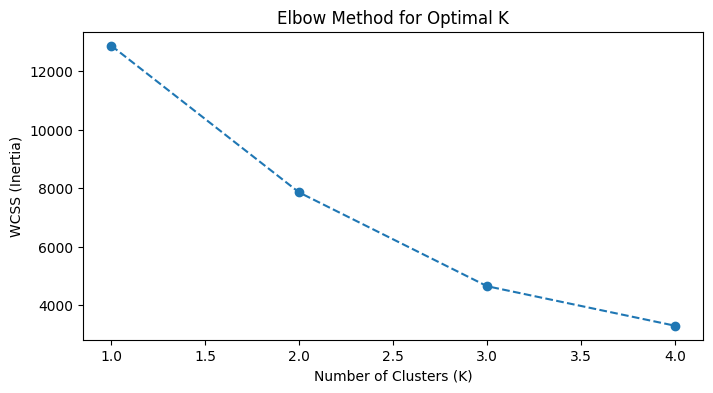

In [5]:
wcss = []
for i in range(1, 5): # Usually 1-10, adjusted here for sample size
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, 5), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.show()

In [6]:
# Initialize and fit the model
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)
cluster_labels = kmeans.fit_predict(x_scaled)

# Add the cluster labels back to our original DataFrame
df['Cluster'] = cluster_labels
print(df.head())

   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1 2010-02-05    1643690.90             0        42.31       2.572   
1      1 2010-02-12    1641957.44             1        38.51       2.548   
2      1 2010-02-19    1611968.17             0        39.93       2.514   
3      1 2010-02-26    1409727.59             0        46.63       2.561   
4      1 2010-03-05    1554806.68             0        46.50       2.625   

          CPI  Unemployment  Cluster  
0  211.096358         8.106        1  
1  211.242170         8.106        1  
2  211.289143         8.106        1  
3  211.319643         8.106        1  
4  211.350143         8.106        1  


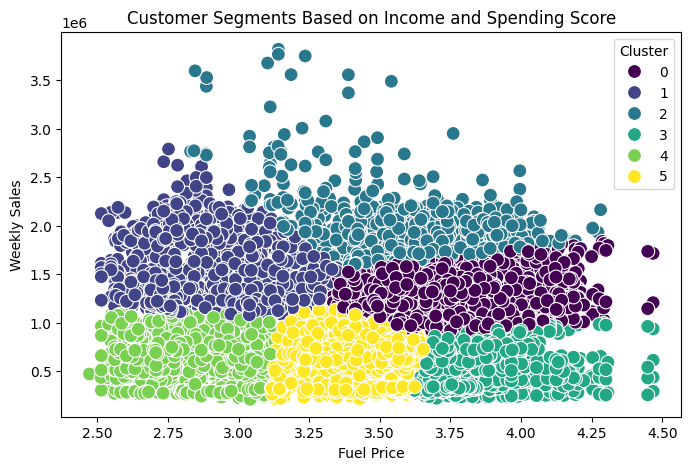

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='Fuel_Price', 
    y='Weekly_Sales', 
    hue='Cluster', 
    data=df, 
    palette='viridis', 
    s=100
)
plt.title('Customer Segments Based on Income and Spending Score')
plt.xlabel('Fuel Price')
plt.ylabel('Weekly Sales')
plt.legend(title='Cluster')
plt.show()